In [3]:
# RAVLT simulation: 2 x 2 design (hormone therapy x exercise)
# Simulated data only -- no real participants.

import numpy as np
import pandas as pd

# ---------------------------------------------------------------
# 1. assumptions
# ---------------------------------------------------------------
rng = np.random.default_rng(seed=42)   # fixed seed = same "random" data every run

N_PER_GROUP   = 40      # participants per group (4 groups -> 160 total)
BASELINE_MEAN = 10.0    # mean delayed recall, women 50-69 (derived from geffen norms)
BASELINE_SD   = 3.0     # between the 2.5 and 3.4 SDs (also in the norms)
R_RETEST      = 0.70    # baseline -> follow-up correlation (test-retest reliability published range 0.6-0.8)

# effect sizes (in words recalled) -- from Schilder et al. 2010 + Aghjayan et al. 2022
TAMOXIFEN_DEFICIT   = 1.0  # H1: how many fewer words tamoxifen recalls than exemestane (Schilder d = 0.43 vs controls, ~1.3 words, so 1.0 is conservative)
WALKING_BENEFIT_EX  = 0.5  # H2: walking benefit in the exemestane group
WALKING_BENEFIT_TAM = 1.2  # H3: walking benefit is larger in the tamoxifen group because greater deficit
                           #     (average of the two = ~0.85 words, matches Aghjayan meta-analysis g = 0.28)

# ---------------------------------------------------------------
# 2. structure of the 4 groups
# ---------------------------------------------------------------
rows = []
for drug in ["tamoxifen", "exemestane"]:
    for exercise in ["walking", "stretching"]:
        for i in range(N_PER_GROUP):
            rows.append({"drug": drug, "exercise": exercise})

df = pd.DataFrame(rows)
df.insert(0, "participant_id", [f"P{i+1:03d}" for i in range(len(df))])

# ---------------------------------------------------------------
# 3. baseline scores (women already taking drug (due to quasi))
# ---------------------------------------------------------------
is_tam  = (df["drug"] == "tamoxifen").astype(float)
is_walk = (df["exercise"] == "walking").astype(float)

baseline_mean = BASELINE_MEAN - TAMOXIFEN_DEFICIT * is_tam
df["baseline_recall"] = baseline_mean + rng.normal(0, BASELINE_SD, len(df))

# ---------------------------------------------------------------
# 4. follow up scores after 12 week program
#    follow-up = expected group mean
#              + R_RETEST -- how far she started above/below her group's average (high starters stay high)
#              + noise-- the overall correlation is about R_RETEST
# ---------------------------------------------------------------
walking_benefit = np.where(is_tam == 1, WALKING_BENEFIT_TAM, WALKING_BENEFIT_EX)
followup_mean = baseline_mean + walking_benefit * is_walk

noise_sd = BASELINE_SD * np.sqrt(1 - R_RETEST**2)
df["delayed_recall"] = (
    followup_mean
    + R_RETEST * (df["baseline_recall"] - baseline_mean)
    + rng.normal(0, noise_sd, len(df))
)

# ---------------------------------------------------------------
# to make the scores more realistic (0-15)
# ---------------------------------------------------------------
for col in ["baseline_recall", "delayed_recall"]:
    df[col] = df[col].round().clip(0, 15).astype(int)

df.to_csv("ravlt_simulated_data.csv", index=False)

# ---------------------------------------------------------------
# checking
# ---------------------------------------------------------------
print(df.head(), "\n")
print("Group means:")
print(df.groupby(["drug", "exercise"])[["baseline_recall", "delayed_recall"]].mean().round(2), "\n")
print("Baseline-follow-up correlation:",
      round(df["baseline_recall"].corr(df["delayed_recall"]), 2))

  participant_id       drug exercise  baseline_recall  delayed_recall
0           P001  tamoxifen  walking               10               9
1           P002  tamoxifen  walking                6               6
2           P003  tamoxifen  walking               11              15
3           P004  tamoxifen  walking               12              10
4           P005  tamoxifen  walking                3               8 

Group means:
                       baseline_recall  delayed_recall
drug       exercise                                   
exemestane stretching             9.75            9.90
           walking                9.28           10.12
tamoxifen  stretching             9.02            8.80
           walking                9.07           10.35 

Baseline-follow-up correlation: 0.57


In [4]:
# ---------------------------------------------------------------
# 5. ANCOVA: does delayed recall differ by drug, exercise, and their
#    interaction, after controlling for baseline recall?
#    (run this cell AFTER the simulation cell)
# ---------------------------------------------------------------
import statsmodels.formula.api as smf
import statsmodels.api as sm

# C() = treat as a category; Sum coding + Type III sums of squares = same as SPSS
model = smf.ols(
    "delayed_recall ~ baseline_recall + C(drug, Sum) * C(exercise, Sum)",
    data=df,
).fit()

anova_table = sm.stats.anova_lm(model, typ=3)

# partial eta squared = effect size for each term
ss_error = anova_table.loc["Residual", "sum_sq"]
anova_table["partial_eta_sq"] = anova_table["sum_sq"] / (anova_table["sum_sq"] + ss_error)
anova_table.loc["Residual", "partial_eta_sq"] = None

print("ANCOVA on delayed recall (baseline recall as covariate):")
print(anova_table.drop(index="Intercept").round(3), "\n")

# adjusted means = group means as if everyone started at the same baseline
avg_baseline = df["baseline_recall"].mean()
groups = df[["drug", "exercise"]].drop_duplicates().copy()
groups["baseline_recall"] = avg_baseline
groups["adjusted_mean"] = model.predict(groups).round(2)
print(f"Adjusted means (at average baseline = {avg_baseline:.2f}):")
print(groups[["drug", "exercise", "adjusted_mean"]].to_string(index=False))

ANCOVA on delayed recall (baseline recall as covariate):
                                sum_sq     df       F  PR(>F)  partial_eta_sq
C(drug, Sum)                     1.014    1.0   0.230   0.632           0.001
C(exercise, Sum)                41.137    1.0   9.340   0.003           0.057
C(drug, Sum):C(exercise, Sum)   10.170    1.0   2.309   0.131           0.015
baseline_recall                352.809    1.0  80.106   0.000           0.341
Residual                       682.666  155.0     NaN     NaN             NaN 

Adjusted means (at average baseline = 9.28):
      drug   exercise  adjusted_mean
 tamoxifen    walking          10.47
 tamoxifen stretching           8.95
exemestane    walking          10.13
exemestane stretching           9.62


A) Homogeneity of regression slopes (want p > .05 for all):
                                                   F  PR(>F)
baseline_recall:C(drug, Sum)                   0.047   0.829
baseline_recall:C(exercise, Sum)               1.241   0.267
baseline_recall:C(drug, Sum):C(exercise, Sum)  0.007   0.934 

B) Levene's test: F = 0.16, p = 0.921 (want p > .05)

C) Shapiro-Wilk: W = 0.989, p = 0.271 (want p > .05)


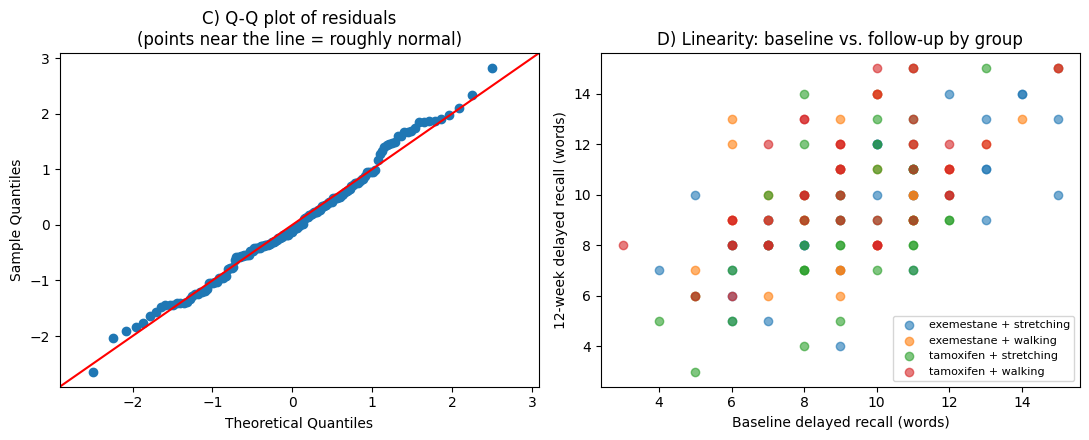

In [5]:
# ---------------------------------------------------------------
# 6. ANCOVA assumption checks
#    (run AFTER the simulation and ANCOVA cells -- uses df and model)
# ---------------------------------------------------------------
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm

# A) homogeneity of regression slopes
#    the baseline -> follow-up relationship should be the same in every group.
#    test: add baseline x group interaction terms; they should NOT be significant
slopes_model = smf.ols(
    "delayed_recall ~ baseline_recall * C(drug, Sum) * C(exercise, Sum)",
    data=df,
).fit()
slopes_table = sm.stats.anova_lm(slopes_model, typ=3)
slope_terms = [t for t in slopes_table.index if "baseline_recall:" in t]
print("A) Homogeneity of regression slopes (want p > .05 for all):")
print(slopes_table.loc[slope_terms, ["F", "PR(>F)"]].round(3), "\n")

# B) homogeneity of variance (Levene's test on the residuals by group)
#    the spread of scores should be similar in all 4 groups
df["residual"] = model.resid
group_resids = [g["residual"] for _, g in df.groupby(["drug", "exercise"])]
lev_stat, lev_p = stats.levene(*group_resids)
print(f"B) Levene's test: F = {lev_stat:.2f}, p = {lev_p:.3f} (want p > .05)\n")

# C) normality of residuals (Shapiro-Wilk + Q-Q plot)
sw_stat, sw_p = stats.shapiro(df["residual"])
print(f"C) Shapiro-Wilk: W = {sw_stat:.3f}, p = {sw_p:.3f} (want p > .05)")

# D) linearity: baseline vs follow-up should look like a straight-line relationship
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sm.qqplot(df["residual"], line="45", fit=True, ax=axes[0])
axes[0].set_title("C) Q-Q plot of residuals\n(points near the line = roughly normal)")

for (drug, exercise), g in df.groupby(["drug", "exercise"]):
    axes[1].scatter(g["baseline_recall"], g["delayed_recall"], alpha=0.6,
                    label=f"{drug} + {exercise}")
axes[1].set_xlabel("Baseline delayed recall (words)")
axes[1].set_ylabel("12-week delayed recall (words)")
axes[1].set_title("D) Linearity: baseline vs. follow-up by group")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

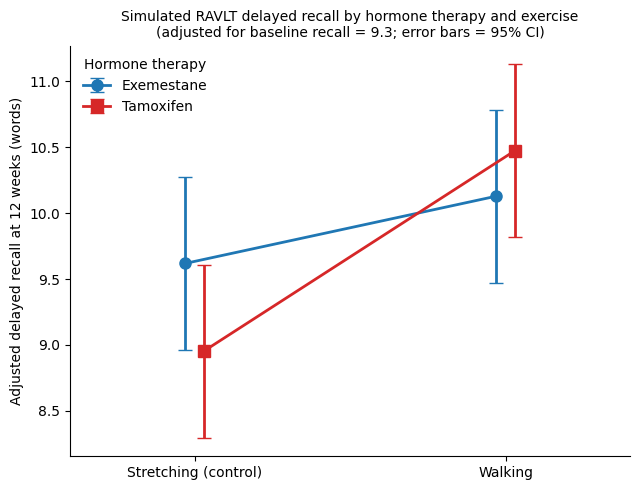

      drug   exercise  adj_mean  ci_low  ci_high
exemestane stretching      9.62    8.96    10.28
exemestane    walking     10.13    9.47    10.78
 tamoxifen stretching      8.95    8.30     9.61
 tamoxifen    walking     10.47    9.82    11.13


In [7]:
# ---------------------------------------------------------------
# 7. main results figure: adjusted means with 95% confidence intervals
#    (run AFTER the simulation and ANCOVA cells -- uses df and model)
# ---------------------------------------------------------------
import pandas as pd
import matplotlib.pyplot as plt

# predicted 12-week recall for each group, as if everyone started at the average baseline
avg_baseline = df["baseline_recall"].mean()
plot_groups = pd.DataFrame({
    "drug":     ["exemestane", "exemestane", "tamoxifen", "tamoxifen"],
    "exercise": ["stretching", "walking",    "stretching", "walking"],
    "baseline_recall": avg_baseline,
})
pred = model.get_prediction(plot_groups).summary_frame(alpha=0.05)
plot_groups["adj_mean"] = pred["mean"].values
plot_groups["ci_low"]   = pred["mean_ci_lower"].values
plot_groups["ci_high"]  = pred["mean_ci_upper"].values

# interaction plot: exercise on the x-axis, one line per drug
fig, ax = plt.subplots(figsize=(6.5, 5))
x_pos = {"stretching": 0, "walking": 1}
styles = {"exemestane": ("#1f77b4", "o", -0.03), "tamoxifen": ("#d62728", "s", 0.03)}

for drug, g in plot_groups.groupby("drug"):
    color, marker, nudge = styles[drug]
    x = [x_pos[e] + nudge for e in g["exercise"]]
    yerr = [g["adj_mean"] - g["ci_low"], g["ci_high"] - g["adj_mean"]]
    ax.errorbar(x, g["adj_mean"], yerr=yerr, color=color, marker=marker,
                markersize=8, linewidth=2, capsize=5, label=drug.capitalize())

ax.set_xticks([0, 1])
ax.set_xticklabels(["Stretching (control)", "Walking"])
ax.set_xlim(-0.4, 1.4)
ax.set_ylabel("Adjusted delayed recall at 12 weeks (words)")
ax.set_title("Simulated RAVLT delayed recall by hormone therapy and exercise\n"
             f"(adjusted for baseline recall = {avg_baseline:.1f}; error bars = 95% CI)",
             fontsize=10)
ax.legend(title="Hormone therapy", frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("ravlt_results.png", dpi=200)
plt.show()

print(plot_groups[["drug", "exercise", "adj_mean", "ci_low", "ci_high"]].round(2).to_string(index=False))

n =  40 per group done
n =  80 per group done
n = 120 per group done
n = 160 per group done
n = 200 per group done
n = 300 per group done
n = 400 per group done

Power (proportion of simulated studies with p < .05):
 n_per_group  total_N  power_drug  power_exercise  power_interaction
          40      160        0.45            0.70               0.16
          80      320        0.74            0.94               0.30
         120      480        0.88            0.99               0.44
         160      640        0.97            1.00               0.51
         200      800        0.98            1.00               0.63
         300     1200        1.00            1.00               0.78
         400     1600        1.00            1.00               0.93


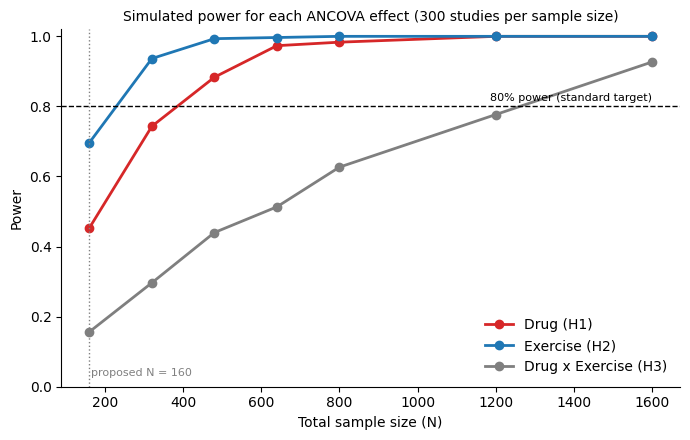

In [8]:
# ---------------------------------------------------------------
# 8. power analysis by simulation
#    power = how often the ANCOVA finds an effect that we KNOW is there.
#    run the whole study many times at different sample sizes and count
#    how often each effect comes out significant (p < .05).
#    (run AFTER the simulation cell -- uses its assumption values)
# ---------------------------------------------------------------
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm
import matplotlib.pyplot as plt

def simulate_study(n_per_group, rng):
    """Make one fake dataset with the same assumptions as the simulation cell."""
    drug     = np.repeat(["tamoxifen", "tamoxifen", "exemestane", "exemestane"], n_per_group)
    exercise = np.repeat(["walking", "stretching", "walking", "stretching"], n_per_group)
    is_tam   = (drug == "tamoxifen").astype(float)
    is_walk  = (exercise == "walking").astype(float)

    baseline = BASELINE_MEAN + rng.normal(0, BASELINE_SD, len(drug))
    walking_benefit = np.where(is_tam == 1, WALKING_BENEFIT_TAM, WALKING_BENEFIT_EX)
    followup_mean = BASELINE_MEAN - TAMOXIFEN_DEFICIT * is_tam + walking_benefit * is_walk
    noise_sd = BASELINE_SD * np.sqrt(1 - R_RETEST**2)
    followup = followup_mean + R_RETEST * (baseline - BASELINE_MEAN) + rng.normal(0, noise_sd, len(drug))

    return pd.DataFrame({
        "drug": drug, "exercise": exercise,
        "baseline_recall": np.clip(np.round(baseline), 0, 15),
        "delayed_recall":  np.clip(np.round(followup), 0, 15),
    })

def run_ancova(data):
    """Return the p-values for drug, exercise, and the interaction."""
    fit = smf.ols("delayed_recall ~ baseline_recall + C(drug, Sum) * C(exercise, Sum)",
                  data=data).fit()
    p = sm.stats.anova_lm(fit, typ=3)["PR(>F)"]
    return p["C(drug, Sum)"], p["C(exercise, Sum)"], p["C(drug, Sum):C(exercise, Sum)"]

N_SIMS = 300                                   # studies per sample size (more = more precise, but slower)
sample_sizes = [40, 80, 120, 160, 200, 300, 400]    # participants PER GROUP (x4 for total N)
power_rng = np.random.default_rng(seed=123)

results = []
for n in sample_sizes:
    pvals = np.array([run_ancova(simulate_study(n, power_rng)) for _ in range(N_SIMS)])
    power = (pvals < 0.05).mean(axis=0)
    results.append({"n_per_group": n, "total_N": 4 * n,
                    "power_drug": power[0], "power_exercise": power[1], "power_interaction": power[2]})
    print(f"n = {n:>3} per group done")

power_table = pd.DataFrame(results)
print("\nPower (proportion of simulated studies with p < .05):")
print(power_table.round(2).to_string(index=False))

# power curve
fig, ax = plt.subplots(figsize=(7, 4.5))
for col, label, color in [("power_drug", "Drug (H1)", "#d62728"),
                          ("power_exercise", "Exercise (H2)", "#1f77b4"),
                          ("power_interaction", "Drug x Exercise (H3)", "#7f7f7f")]:
    ax.plot(power_table["total_N"], power_table[col], marker="o", linewidth=2, color=color, label=label)

ax.axhline(0.80, linestyle="--", color="black", linewidth=1)
ax.text(power_table["total_N"].max(), 0.81, "80% power (standard target)", ha="right", va="bottom", fontsize=8)
ax.axvline(160, linestyle=":", color="gray", linewidth=1)
ax.text(165, 0.03, "proposed N = 160", fontsize=8, color="gray")
ax.set_xlabel("Total sample size (N)")
ax.set_ylabel("Power")
ax.set_ylim(0, 1.02)
ax.set_title(f"Simulated power for each ANCOVA effect ({N_SIMS} studies per sample size)", fontsize=10)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("ravlt_power.png", dpi=200)
plt.show()